# La región de señal y la región de ruido

**Pregunta:** ¿Cómo compra precisión dentro de la región de señal el renunciar al control de la luz fuera de ella, y cuánto del plano focal hay que ceder?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebook 01 de este tema (el disco, el error y Gerchberg-Saxton simple)
- **Tiempo de lectura:** unos 50 minutos; el notebook se ejecuta en unos 2 minutos

## Objetivos

Gerchberg-Saxton simple obliga a cada bin del plano focal a tomar un valor: el objetivo dentro de la forma y cero en todo lo demás. Un holograma de solo fase no puede lograrlo, y el disco del notebook anterior termina con un error de 0,4411. La libertad de amplitud de región mixta (MRAF) levanta la restricción fuera de una región elegida y deja que la luz vaya allí. Este notebook construye esa región a mano, como una ventana cuadrada de tamaño creciente alrededor del disco, y corre el MRAF del producto en cada ventana con el parámetro de mezcla fijo en 0,3. Verá a dónde va la potencia, cómo depende el error de cuánta grilla queda libre, por qué una ventana que cubre toda la grilla da exactamente Gerchberg-Saxton simple, cómo se ve la luz en la región libre y si el margen oscuro alrededor de la forma importa. Al final podrá elegir una región de señal para un objetivo con forma y decir qué cuesta.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, y luego los módulos del pipeline por su ruta
import copy
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.core import score
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m04_gs, m08_mraf

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, sin conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C04: un disco de 15 um de radio en un modulador espacial de luz (SLM) de 256 por 256 píxeles, rellenado hasta una grilla focal de 512 por 512 bins, 30 iteraciones y un margen de región de señal de 3 bins. El dispositivo del caso (8 bits y crosstalk) no se usa aquí.

In [2]:
# el caso C04 da el SLM, el haz y el disco; las copias de su registro cambian solo el margen de la región de señal
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C04_disc_crosstalk"]
setup = setup_of(rec)
disc = target_of(rec)
seed, budget = rec["seed"], Budget(rec["budget"]["iterations"])
n, c = setup.n_fft, setup.n_fft // 2
shape = disc.amplitude > 0
print(f"malla focal {n} x {n}, forma {int(shape.sum())} bins")
print(f"margen del caso {rec['target']['signal_margin_bins']} bins, iteraciones {budget.iterations}")

malla focal 512 x 512, forma 2861 bins
margen del caso 3 bins, iteraciones 30


## Método

**La regla.** MRAF (Pasienski y DeMarco 2008, Ec. 1, https://doi.org/10.1364/OE.16.002176) divide la grilla focal en una región de señal SR y una región de ruido NR y reemplaza el campo tras cada pasada por $G = \{ m\,T|_{SR} + (1-m)\,|E|\,|_{NR} \}\,e^{i \arg E}$, y luego vuelve al SLM con $\phi \leftarrow \arg \mathcal{F}^{-1}\{G\}$. Dentro de SR la amplitud se fuerza a $mT$; en NR conserva $1-m$ de lo que el holograma hizo, de modo que la potencia que la forma no necesita se escurre hacia NR. Con $m = 1$ la región de ruido se multiplica por cero, lo que es Gerchberg-Saxton simple, y el M04 del producto sobre un objetivo con forma es exactamente eso. El notebook fija $m = 0.3$, el valor por defecto del producto, y varía la región; el notebook siguiente varía $m$.

**La región.** La región de señal del caso es el disco dilatado en 3 bins, de modo que NR es casi toda la grilla. Para ver el efecto del tamaño de NR, el notebook construye sus propias regiones: una ventana cuadrada de semiancho $h$ bins alrededor del eje, unida con la forma, y una NR que es todo lo que queda fuera de la ventana. El objetivo es el mismo disco. El error es el del notebook 01, $\eta = \sqrt{\langle ((sI - T^2)/T^2)^2 \rangle}$ sobre la forma erosionada en una celda de resolución (Ec. 2 del mismo artículo), y la potencia se reparte en tres porciones: en la forma, en el resto de SR y en NR.

El primer paso construye las ventanas. La celda define una función que devuelve el objetivo con forma para un semiancho e imprime, para semianchos de 48, 96, 144, 192, 240 y 256 bins, cuántos bins son de señal y cuántos de ruido. Un semiancho de 256 cubre toda la grilla de 512.

In [3]:
# una región de señal hecha a mano: una ventana cuadrada de semiancho h bins alrededor del eje, más la forma misma
def windowed(half_width):
    mask = np.zeros((n, n), dtype=bool)
    mask[c - half_width:c + half_width, c - half_width:c + half_width] = True
    return Target.from_field(disc.amplitude, mask | shape)


windows = (48, 96, 144, 192, 240, 256)
for h in windows:
    free = ~windowed(h).mask
    print(f"h = {h:3d}: región de señal {int(windowed(h).mask.sum()):6d},", end=" ")
    print(f"región de ruido {int(free.sum()):6d} bins = {100 * free.mean():5.1f} %")

h =  48: región de señal   9216, región de ruido 252928 bins =  96.5 %
h =  96: región de señal  36864, región de ruido 225280 bins =  85.9 %
h = 144: región de señal  82944, región de ruido 179200 bins =  68.4 %
h = 192: región de señal 147456, región de ruido 114688 bins =  43.8 %
h = 240: región de señal 230400, región de ruido  31744 bins =  12.1 %
h = 256: región de señal 262144, región de ruido      0 bins =   0.0 %


La región de ruido va de 96,5 por ciento de la grilla con semiancho 48 a 12,1 por ciento con 240 y ninguna con 256, donde cada bin pertenece a la región de señal. El segundo paso fija la referencia. La celda corre M04 sobre el disco con la región de señal propia del caso y reparte su potencia en tres porciones, en la forma, en el margen de la región de señal y fuera de él, junto al error.

In [4]:
# M04 sobre el disco: la región de ruido se fuerza a cero, la referencia de todo el notebook
def power_split(phi, target):
    power = np.abs(forward.fft_focal_field(phi, setup)) ** 2 / setup.n_pix**2
    return power[shape].sum(), power[target.mask & ~shape].sum(), power[~target.mask].sum()


plain = m04_gs.run(setup, disc, budget=budget, rng=Rng(seed))
inside, margin, outside = power_split(plain.phi, disc)
print(f"M04: error {plain.history[-1]['error']:.4f}")
print(f"potencia en la forma {inside:.4f}, en el margen de la región de señal {margin:.4f}, fuera {outside:.4f}")
# el inicio solo: la lente de Fresnel de 20 ondas desde la que parte MRAF, evaluada como todo holograma
x, y = geometry.slm_grid(setup)
fresnel_start = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
start_error = score.signal_error_pct(forward.fft_focal_field(fresnel_start, setup), disc, setup) / 100.0
start_inside = power_split(fresnel_start, disc)[0]
print(f"el inicio de Fresnel solo: error {start_error:.4f}, potencia en la forma {start_inside:.4f}")

M04: error 0.4411
potencia en la forma 0.9531, en el margen de la región de señal 0.0090, fuera 0.0379
el inicio de Fresnel solo: error 0.0322, potencia en la forma 0.0754


M04 pone 0,9531 de la potencia de entrada en la forma, 0,0090 en el margen y 0,0379 fuera de él, con el error de 0,4411 ya visto. No tiene región de ruido, de modo que la luz que no está en la forma no tiene adónde ir salvo el margen y el resto de la grilla, que entre ambos retienen 0,0469. El tercer paso es el experimento. Para cada semiancho la celda corre el MRAF del producto en esa región e imprime el error y las tres porciones de potencia.

In [5]:
# MRAF (M08, mezcla 0.3) en cada región hecha a mano: el error y adónde va la potencia
runs = {}
for h in windows:
    target = windowed(h)
    runs[h] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
    inside, margin, outside = power_split(runs[h].phi, target)
    print(f"h = {h:3d}: error {runs[h].history[-1]['error']:.4f}, potencia en la forma {inside:.4f}, "
          f"margen {margin:.4f}, región de ruido {outside:.4f}")

h =  48: error 0.0482, potencia en la forma 0.1787, margen 0.0010, región de ruido 0.8203
h =  96: error 0.0405, potencia en la forma 0.1800, margen 0.0015, región de ruido 0.8185
h = 144: error 0.0687, potencia en la forma 0.1791, margen 0.0031, región de ruido 0.8178
h = 192: error 0.2029, potencia en la forma 0.1794, margen 0.0083, región de ruido 0.8122
h = 240: error 0.2320, potencia en la forma 0.1874, margen 0.0299, región de ruido 0.7827
h = 256: error 0.4411, potencia en la forma 0.9531, margen 0.0469, región de ruido 0.0000


Los errores son 0,0482, 0,0405, 0,0687, 0,2029, 0,2320 y 0,4411 para los semianchos 48, 96, 144, 192, 240 y 256. Con una región libre de 85,9 por ciento de la grilla el error baja a 0,0405, once veces menor que el del lazo simple, y con 12,1 por ciento es 0,2320, la mitad. La potencia en la forma es de unos 0,18 para toda ventana, de 0,1787 a 0,1874, y la región de ruido guarda entre 0,7827 y 0,8203 de la potencia de entrada: la ventana decide la precisión y no la porción de potencia en la forma, lo que sugiere que, con este valor de la mezcla, es la mezcla la que fija esa porción. La última fila es la grilla entera, y tiene los números de M04 hasta el último dígito: error 0,4411 y 0,9531 de la potencia en la forma. La celda siguiente prueba esa identidad directamente, comparando las dos fases. El inicio de Fresnel desde el que parte toda corrida tiene un error de 0,0322 con 0,0754 de la potencia en la forma (impreso en la celda 9): MRAF conserva casi toda esa precisión con las regiones de ruido más anchas (0,0405 y 0,0482) mientras sube la potencia en la forma a cerca de 0,18, y el lazo simple es el que la pierde (0,4411).

In [6]:
# con la región de ruido vacía MRAF no tiene a dónde mover la potencia: se compara su fase con la de M04
gap = np.angle(np.exp(1j * (runs[256].phi - plain.phi)))
print(f"mayor diferencia de fase entre M04 y MRAF con h = 256 (rad): {np.abs(gap).max():.2e}")
print(f"errores: M04 {plain.history[-1]['error']:.4f}, MRAF h = 256 {runs[256].history[-1]['error']:.4f}")

mayor diferencia de fase entre M04 y MRAF con h = 256 (rad): 4.84e-10
errores: M04 0.4411, MRAF h = 256 0.4411


La mayor diferencia entre la fase de M04 y la de MRAF con la ventana de semiancho 256 es 4,84e-10 rad, error de redondeo, y ambos errores son 0,4411. Sin región de ruido, la mezcla $m$ escala todo el objetivo por una constante, y una constante no cambia la fase que conserva un paso de Gerchberg-Saxton. Así, Gerchberg-Saxton simple es el extremo de esta familia y MRAF no necesita un segundo algoritmo: necesita una región. La figura dibuja todo el experimento. El panel izquierdo apila, para cada configuración, la potencia en la forma (azul), en el margen de la región de señal (naranja) y en la región de ruido (verde); el panel derecho grafica el error de MRAF en un eje logarítmico frente a la fracción de la grilla que es ruido, con el lazo simple como línea punteada y cada punto rotulado con su semiancho.

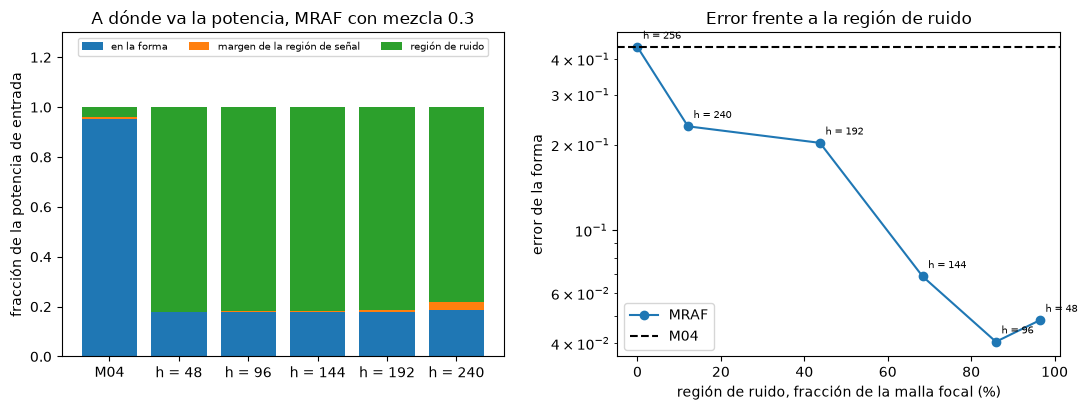

In [7]:
# izquierda: adónde va la potencia; derecha: el error frente a la fracción de la grilla para ruido
labels = ["M04"] + [f"h = {h}" for h in windows[:-1]]
splits = [power_split(plain.phi, disc)] + [power_split(runs[h].phi, windowed(h)) for h in windows[:-1]]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))
bottom = np.zeros(len(labels))
for k, name in enumerate(("en la forma", "margen de la región de señal", "región de ruido")):
    part = np.array([s[k] for s in splits])
    left.bar(labels, part, bottom=bottom, label=name)
    bottom += part
left.set_ylabel("fracción de la potencia de entrada")
left.set_title("A dónde va la potencia, MRAF con mezcla 0.3")
left.set_ylim(0, 1.3)
left.legend(loc="upper center", ncol=3, fontsize=7.5)
share = [100 * (~windowed(h).mask).mean() for h in windows]
right.semilogy(share, [runs[h].history[-1]["error"] for h in windows], "o-", label="MRAF")
for h, x_share in zip(windows, share):
    point = (x_share, runs[h].history[-1]["error"])
    right.annotate(f"h = {h}", point, textcoords="offset points", xytext=(4, 6), fontsize=7.5)
right.axhline(plain.history[-1]["error"], color="k", ls="--", label="M04")
right.set_xlabel("región de ruido, fracción de la malla focal (%)")
right.set_ylabel("error de la forma")
right.set_title("Error frente a la región de ruido")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, M04 conserva 0,9531 de la potencia en la forma, y cada barra de MRAF tiene la misma base azul de unos 0,18 y una cima verde que guarda el resto, de modo que toda la diferencia entre preciso e impreciso está en dónde se deja que esté el otro cuatro quintos de la luz. A la derecha, el error no cae en proporción al área libre: baja de 0,4411 a 0,2320 y 0,2029 cuando 12,1 y 43,8 por ciento de la grilla son libres, y luego a 0,0687, 0,0405 y 0,0482 con 68,4, 85,9 y 96,5 por ciento. Toca fondo cerca del punto de 86 por ciento, y la pequeña alza con 96,5 por ciento es del tamaño de la variación que el último paso encuentra entre márgenes. MRAF parte de una fase de Fresnel fija, así que repetir una corrida da los mismos dígitos; pero un cambio pequeño de la región mueve el error en cerca de 0,01, de modo que ventanas vecinas que difieren en menos que eso no quedan ordenadas. La figura muestra potencia y error y no cómo se ve la luz libre, que es el gráfico siguiente.

La celda dibuja la potencia focal en escala logarítmica para la ventana de señal menor, de semiancho 48, que deja la región de ruido más ancha, y para la mayor, de semiancho 240, que deja la más delgada, con el borde de la ventana como una línea cian.

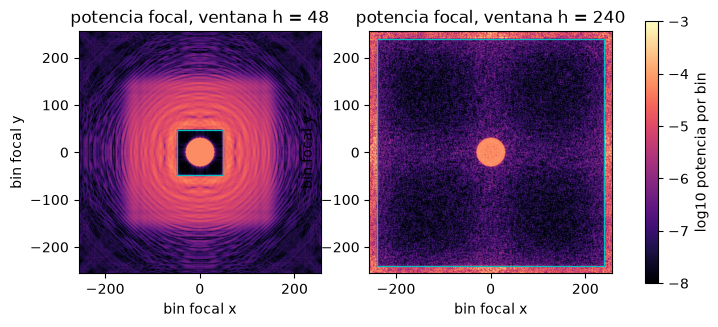

In [8]:
# la potencia focal en escala log para la ventana más chica y la más grande que no es toda la grilla
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.0))
for ax, h in zip(axes, (48, 240)):
    power = np.abs(forward.fft_focal_field(runs[h].phi, setup)) ** 2 / setup.n_pix**2
    image = ax.imshow(np.log10(power + 1e-9), origin="lower", vmin=-8, vmax=-3, cmap="magma", extent=(-c, c, -c, c))
    ax.plot([-h, h, h, -h, -h], [-h, -h, h, h, -h], color="c", lw=0.9)
    ax.set_title(f"potencia focal, ventana h = {h}")
    ax.set_xlabel("bin focal x")
    ax.set_ylabel("bin focal y")
fig.colorbar(image, ax=axes, label="log10 potencia por bin", shrink=0.85)
plt.show()

Con semiancho 48, a la izquierda, el disco es un punto brillante y plano en un cuadrado oscuro que es la región de señal, y la región de ruido lleva un halo suave con anillos concéntricos varias veces mayores que la ventana: la luz que el disco no quiere se extiende sobre unos 150 bins en todas direcciones y es tenue en todas partes, más de un orden de magnitud bajo el disco por bin. Con semiancho 240, a la derecha, la ventana es casi toda la grilla, el interior es moteado oscuro, y la luz se apila contra el borde de la ventana en el marco delgado que queda: allí es más brillante que en cualquier otro lugar fuera del disco, porque no tiene otro lugar adonde ir. Una lectura de esto, que aquí no se prueba, es que una región libre delgada no puede absorber la luz sin subir el moteado dentro de la región de señal. La figura no muestra si el halo importa para un experimento. Un potencial con 0,8 de la luz en un halo tenue podría calentar los átomos o actuar sobre un gas que no debería sentirlo, lo que el error no puede decir.

El último paso pregunta por el margen oscuro que el caso añade alrededor de la forma. La celda vuelve a correr MRAF sobre el disco con márgenes de 0 y 12 bins, cambiando el margen en una copia del registro del caso, y junto a ellos el margen propio del caso, de 3.

In [9]:
# el margen oscuro: el margen de 3 bins del caso frente a ninguno y 12 bins, a través del registro del objetivo
for bins in (0, 12):
    variant = copy.deepcopy(rec)
    variant["target"]["signal_margin_bins"] = bins
    target = target_of(variant)
    res = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
    inside = power_split(res.phi, target)[0]
    print(f"margen {bins:2d} bins: error {res.history[-1]['error']:.4f}, potencia en la forma {inside:.4f}")
res = m08_mraf.run(setup, disc, budget=budget, rng=Rng(seed), mixing=0.3)
inside = power_split(res.phi, disc)[0]
print(f"margen  3 bins: error {res.history[-1]['error']:.4f}, potencia en la forma {inside:.4f}")

margen  0 bins: error 0.0460, potencia en la forma 0.1696
margen 12 bins: error 0.0585, potencia en la forma 0.1641
margen  3 bins: error 0.0517, potencia en la forma 0.1712


Un margen de 0 bins da un error de 0,0460 con 0,1696 de la potencia en la forma, 3 bins dan 0,0517 y 0,1712, y 12 bins dan 0,0585 y 0,1641. El margen mueve el error en unos 0,01 en un rango de 12 bins, que es el orden de las diferencias entre las ventanas con la región de ruido más ancha (semianchos 48 y 96), de modo que estos números no ordenan los tres márgenes. Dicen que el margen es una elección menor aquí frente al tamaño de la región libre, cuyo efecto es un factor de diez. El margen importa por otra razón que los números no muestran: un margen oscuro saca la luz de los vecinos de la forma, lo que un experimento con átomos cerca del disco puede necesitar.

## Resultados

**Respuesta:** Ceder el control de la luz fuera de la región de señal permite que el holograma deje de transigir dentro de ella: con MRAF y mezcla 0,3, una región libre de 85,9 por ciento de la grilla focal baja el error del disco de 0,4411 a 0,0405, un factor de once, e incluso 12,1 por ciento de la grilla lo baja a 0,2320. La precisión necesita una región libre y luego se satura: de 68,4 a 96,5 por ciento de la grilla el error queda entre 0,0405 y 0,0687, mientras que bajo 44 por ciento es al menos 0,2029. Ninguna ventana baja del error del inicio de Fresnel solo, 0,0322: MRAF conserva casi toda su precisión (0,0405) y más que duplica su potencia en la forma (de 0,0754 a cerca de 0,18), y es el lazo simple el que la pierde. El precio es potencia: la forma conserva unos 0,18 de la potencia de entrada para toda ventana menor que la grilla entera, de 0,1787 a 0,1874, frente a 0,9531 del lazo simple, y la región de ruido guarda entre 0,7827 y 0,8203 de ella. Sin región libre la respuesta es Gerchberg-Saxton simple hasta el redondeo, 4,84e-10 rad en la fase. El margen oscuro de 0, 3 o 12 bins cambia el error entre 0,0460 y 0,0585 y no decide el asunto. El notebook corrió un caso y un valor de la mezcla; MRAF desde su inicio de Fresnel fijo da los mismos dígitos al repetirse, pero la prueba de márgenes muestra que un cambio pequeño de la región mueve el error en cerca de 0,01, de modo que diferencias de ese tamaño entre ventanas vecinas no las ordenan, y no probó qué hace la luz libre a un experimento.

## Resumen

La precisión sobre un objetivo con forma viene de la región donde no se le pide nada al algoritmo. Una ventana que deja libre de 68 a 96 por ciento de la grilla lleva el disco a un error de 0,04 a 0,07, una ventana que no deja nada es Gerchberg-Saxton simple, y entre ambas el error baja con el área libre. El inicio de Fresnel solo ya tiene un error de 0,0322 con 0,0754 de la potencia en la forma: MRAF conserva esa precisión y más que duplica la potencia, y es el lazo simple el que la pierde. El costo es que cuatro quintos de la luz van a un halo. El notebook siguiente toma el parámetro de mezcla, que fija cuánta luz conserva la forma, y compara el MRAF del producto con el de slmsuite en un disco y un anillo.

## Referencias

- Pasienski y DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.